# Ejercicio completo P1
![logo ITQ](img/ITQ.png) 

**Nombre:** Adrian Lara Ramos

**Fecha:** *11-11-2026*


**Link del repositorio:** 

In [64]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [65]:
from ucimlrepo import fetch_ucirepo

# Descargar el dataset de hospitales con pacientes diabéticos
dataset = fetch_ucirepo(id=296)

# Crear una copia original de los datos
df = dataset.data.original.copy()

# Mostrar cantidad de filas y columnas
print("Filas y columnas:", df.shape)

# Verificar que tenga más de 100.000 registros
assert len(df) > 100_000

# Mostrar las primeras 5 filas
display(df.head())

# Mostrar el diccionario de variables
display(dataset.variables)

# Guardar los datos originales
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

C:\Users\adria\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


### Resultado: Descarga del dataset

Se descargó correctamente el conjunto de datos médicos desde el repositorio UCI Machine Learning.

**Resultados obtenidos:**
- **101.766 filas:** representan hospitalizaciones de pacientes con diabetes.
- **50 columnas:** contienen información médica, demográfica y hospitalaria.
- **Primeros 5 registros:** permiten visualizar la estructura del dataset.

Se identificó una advertencia de tipos mixtos en la variable `payer_code`, que será considerada durante la revisión de calidad de datos.

**Conclusión:** La carga fue exitosa y cumple con el requisito de superar los 100.000 registros.



## Fase 1: Comprensión del negocio (CRISP-DM)

### Planteamiento del problema
Las readmisiones hospitalarias representan un desafío para los centros médicos, debido a que pueden incrementar los costos y afectar la atención de los pacientes.

Esta práctica busca comprender las características de las hospitalizaciones de pacientes con diabetes mediante el análisis exploratorio de datos.

### Objetivo general
Analizar y preparar los datos de hospitalizaciones de pacientes con diabetes, aplicando técnicas de limpieza, normalización Min-Max y estandarización Z-score mediante Python.

### Preguntas de análisis
1. ¿Cómo se distribuyen las principales variables cuantitativas de las hospitalizaciones?
2. ¿Qué diferencias existen entre los datos originales, normalizados y estandarizados?
3. ¿Cómo se distribuyen las categorías de readmisión hospitalaria?

### Criterios de éxito
- Analizar los 101.766 registros del dataset.
- Identificar valores faltantes, duplicados y atípicos.
- Seleccionar siete variables cuantitativas.
- Aplicar correctamente MinMaxScaler y StandardScaler.
- Verificar los resultados mediante estadísticas y gráficos.

### Variable de referencia: readmitted
- **NO:** no se registró una readmisión.
- **<30:** readmisión en menos de 30 días.
- **>30:** readmisión después de 30 días.

Esta variable es categórica y no será normalizada ni estandarizada.

### Limitaciones
Los datos corresponden al periodo 1999-2008 y no representan necesariamente las condiciones hospitalarias actuales.

Un mismo paciente puede tener varias hospitalizaciones. Por confidencialidad, no se intentará identificar a ninguna persona.

El análisis será exclusivamente académico y descriptivo; no permitirá realizar diagnósticos médicos ni establecer relaciones causales.


In [66]:

# Fase 2: Comprensión de los datos

# Dimensiones del dataset
print("Cantidad de hospitalizaciones:", len(df))
print("Cantidad de columnas:", df.shape[1])

# Cantidad de pacientes únicos
print("Pacientes únicos:", df["patient_nbr"].nunique())

# Mostrar los nombres de todas las columnas
print("\nColumnas del dataset:")
print(df.columns.tolist())

# Mostrar información general
print("\nInformación del dataset:")
df.info()


Cantidad de hospitalizaciones: 101766
Cantidad de columnas: 50
Pacientes únicos: 71518

Columnas del dataset:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 101766 


### Interpretación de resultados

Se analizaron las dimensiones y la estructura del conjunto de datos.

El dataset contiene 101.766 hospitalizaciones y 50 variables. Mediante `patient_nbr` se identifica la cantidad de pacientes únicos, permitiendo distinguir entre el número de hospitalizaciones y el número de personas atendidas.

La función `df.info()` permite identificar los tipos de datos y la cantidad de valores no nulos por columna, facilitando la detección de posibles problemas de calidad.


In [67]:

import pandas as pd
import numpy as np

# Crear copia para analizar los datos faltantes
df_revision = df.copy()

# Identificar valores nulos y el marcador ?
faltantes = df_revision.isna() | df_revision.astype(
    "string"
).eq("?")

# Contar valores faltantes por columna
tabla_faltantes = pd.DataFrame({
    "Cantidad de faltantes": faltantes.sum(),
    "Porcentaje (%)": faltantes.mean() * 100
})

# Ordenar de mayor a menor
tabla_faltantes = tabla_faltantes.sort_values(
    "Cantidad de faltantes", ascending=False
)

display(tabla_faltantes.round(2))


,Cantidad de faltantes,Porcentaje (%)
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.4
diag_2,358,0.35
diag_1,21,0.02
encounter_id,0,0.0



### Análisis de valores faltantes

Se identificaron los valores ausentes del conjunto de datos mediante las funciones `isna()` y `eq("?")`.

Se calculó la cantidad y el porcentaje de datos faltantes por columna para determinar cuáles presentan problemas de calidad.

Estos resultados permitirán definir estrategias de limpieza sin modificar innecesariamente la información original.

**Interpretación:** Las columnas con mayor porcentaje de ausencia requieren una revisión antes de ser utilizadas en el análisis. No todas las categorías representan valores faltantes; por ejemplo, `None` puede tener un significado propio.


In [68]:

# Identificar filas completamente duplicadas
duplicados = df.duplicated().sum()

# Identificar IDs de hospitalización repetidos
duplicados_encuentros = df["encounter_id"].duplicated().sum()

# Identificar pacientes registrados más de una vez
pacientes_repetidos = df["patient_nbr"].duplicated().sum()

print("Filas duplicadas:", duplicados)
print("ID de hospitalizaciones repetidos:", duplicados_encuentros)
print("Registros adicionales de pacientes repetidos:", pacientes_repetidos)
print("Pacientes únicos:", df["patient_nbr"].nunique())


Filas duplicadas: 0
ID de hospitalizaciones repetidos: 0
Registros adicionales de pacientes repetidos: 30248
Pacientes únicos: 71518



### Análisis de registros duplicados

Se verificó la existencia de filas duplicadas mediante `duplicated()`.

También se analizaron los identificadores `encounter_id` y `patient_nbr`.

**Interpretación:** La repetición de `patient_nbr` no significa necesariamente que exista un error, ya que un mismo paciente puede haber sido hospitalizado varias veces.

Por este motivo, no se eliminarán automáticamente los registros con pacientes repetidos.


In [69]:

# Seleccionar las siete variables cuantitativas
variables = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Crear copia de las variables
df_numerico = df[variables].copy()

# Convertirlas a valores numéricos
for columna in variables:
    df_numerico[columna] = pd.to_numeric(
        df_numerico[columna], errors="coerce"
    )

# Mostrar estadísticas descriptivas
estadisticas = df_numerico.describe().T

display(estadisticas.round(2))


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0



### Análisis estadístico de las variables

Se calcularon las estadísticas descriptivas de siete variables cuantitativas relacionadas con las hospitalizaciones.

- **Media:** representa el promedio de los valores.
- **Mediana (50%):** representa el valor central de los datos.
- **Desviación estándar:** indica la dispersión de los valores respecto a su media.
- **Mínimo y máximo:** muestran los extremos observados.
- **Cuartiles (25%, 50%, 75%):** permiten conocer la distribución de los datos.

**Interpretación:** Estas estadísticas permiten identificar diferencias de escala, posibles distribuciones asimétricas y valores extremos antes de aplicar la normalización y estandarización.


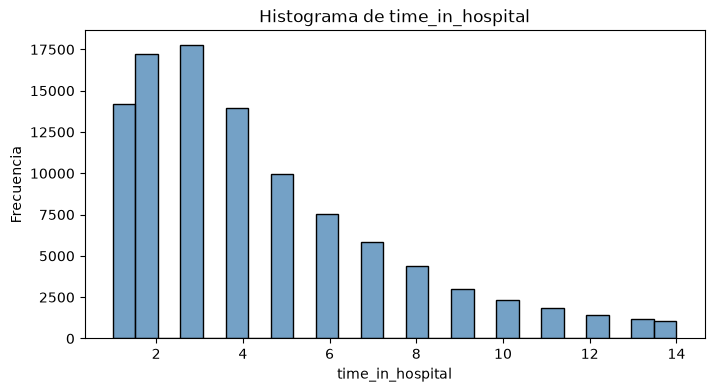

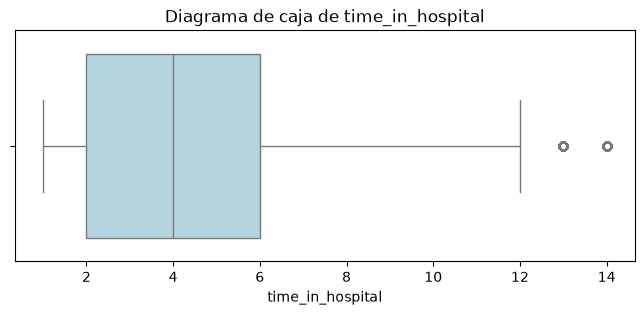

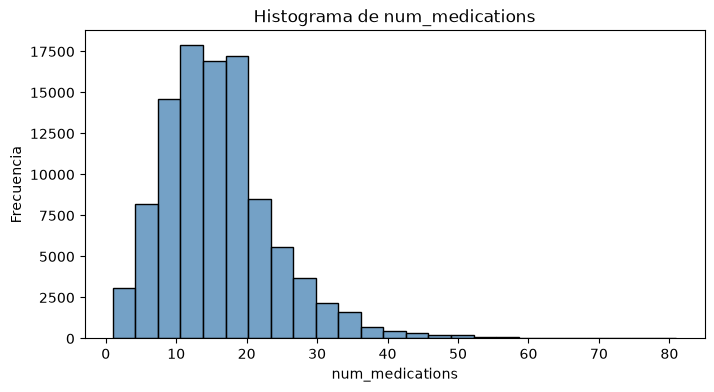

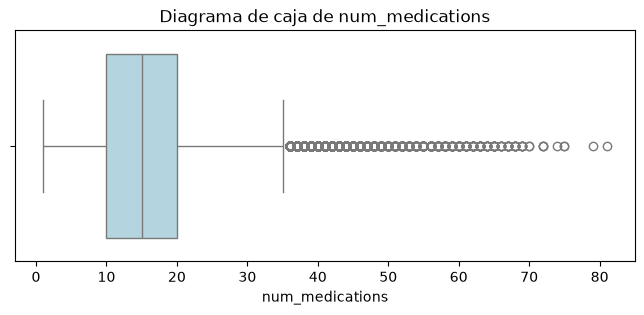

In [70]:

import matplotlib.pyplot as plt
import seaborn as sns

variables_graficos = [
    "time_in_hospital",
    "num_medications"
]

for columna in variables_graficos:

    # Histograma
    plt.figure(figsize=(8, 4))
    sns.histplot(df_numerico[columna].dropna(),
                 bins=25, color="steelblue")
    plt.title(f"Histograma de {columna}")
    plt.xlabel(columna)
    plt.ylabel("Frecuencia")
    plt.show()

    # Diagrama de caja
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_numerico[columna],
                color="lightblue")
    plt.title(f"Diagrama de caja de {columna}")
    plt.show()



### Interpretación de histogramas y diagramas de caja

**Histograma de `time_in_hospital`:** Permite visualizar cuántas hospitalizaciones corresponden a cada duración y reconocer los tiempos de estancia más frecuentes.

**Diagrama de caja de `time_in_hospital`:** Representa la mediana, los cuartiles y posibles valores atípicos de la duración hospitalaria.

**Histograma de `num_medications`:** Permite analizar la distribución del número de medicamentos administrados durante las hospitalizaciones.

**Diagrama de caja de `num_medications`:** Facilita la identificación de hospitalizaciones con cantidades de medicamentos inusualmente altas.

Los gráficos permiten comprender la distribución de los datos antes de aplicar técnicas de escalamiento.


,Frecuencia,Porcentaje (%)
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


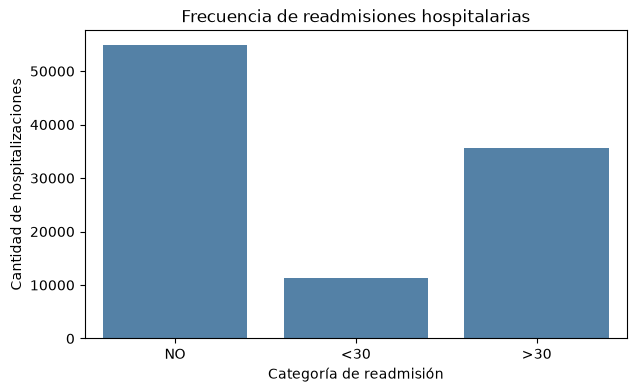

In [71]:

# Calcular frecuencia por categoría
frecuencias = df["readmitted"].value_counts()

# Calcular porcentajes
porcentajes = df["readmitted"].value_counts(
    normalize=True
) * 100

tabla_readmision = pd.DataFrame({
    "Frecuencia": frecuencias,
    "Porcentaje (%)": porcentajes
})

display(tabla_readmision.round(2))

# Visualizar categorías
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="readmitted",
    order=["NO", "<30", ">30"],
    color="steelblue"
)

plt.title("Frecuencia de readmisiones hospitalarias")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Cantidad de hospitalizaciones")
plt.show()



### Análisis de readmisión hospitalaria

Se calcularon las frecuencias y porcentajes de la variable categórica `readmitted`.

Esta variable contiene tres categorías:

- `NO`: no se registró una readmisión.
- `<30`: readmisión en menos de 30 días.
- `>30`: readmisión después de 30 días.

El gráfico permite comparar visualmente la frecuencia de cada categoría.

**Interpretación:** La distribución obtenida permite identificar qué tipo de readmisión es más frecuente en el conjunto de hospitalizaciones analizado.


In [72]:

# Detectar valores atípicos con el método IQR
variables_outliers = [
    "time_in_hospital",
    "num_medications"
]

resultados_outliers = []

for columna in variables_outliers:
    datos = df_numerico[columna].dropna()

    Q1 = datos.quantile(0.25)
    Q3 = datos.quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = (
        (datos < limite_inferior) |
        (datos > limite_superior)
    )

    cantidad = outliers.sum()
    porcentaje = cantidad / len(datos) * 100

    resultados_outliers.append({
        "Variable": columna,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Cantidad outliers": cantidad,
        "Porcentaje (%)": porcentaje
    })

tabla_outliers = pd.DataFrame(resultados_outliers)

display(tabla_outliers.round(2))


,Variable,Límite inferior,Límite superior,Cantidad outliers,Porcentaje (%)
0,time_in_hospital,-4.0,12.0,2252,2.21
1,num_medications,-5.0,35.0,2557,2.51



### Detección de valores atípicos mediante IQR

Se utilizó el rango intercuartílico (IQR) para identificar valores atípicos en dos variables cuantitativas.

**Fórmulas utilizadas:**

- IQR = Q3 - Q1
- Límite inferior = Q1 - 1.5 × IQR
- Límite superior = Q3 + 1.5 × IQR

Los valores que quedan fuera de estos límites se consideran posibles valores atípicos desde el punto de vista estadístico.

**Decisión:** Se conservarán los valores atípicos para el análisis, porque podrían representar hospitalizaciones reales con características poco frecuentes. No se eliminarán únicamente por superar los límites del IQR.


In [73]:

# Crear el diccionario de las 50 variables

# Obtener información de la documentación oficial UCI
diccionario = dataset.variables.copy()

# Agregar el tipo de dato observado en Python
diccionario["tipo_observado"] = diccionario["name"].apply(
    lambda nombre: str(df[nombre].dtype)
)

# Definir el tipo conceptual de cada variable
variables_cuantitativas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

identificadores = ["encounter_id", "patient_nbr"]

def clasificar_variable(nombre):
    if nombre in identificadores:
        return "Identificador"
    elif nombre in variables_cuantitativas:
        return "Cuantitativa discreta"
    else:
        return "Categórica"

diccionario["tipo_conceptual"] = diccionario["name"].apply(
    clasificar_variable
)

# Agregar unidades o categorías
def unidades_variable(nombre):
    if nombre == "time_in_hospital":
        return "Días"
    elif nombre in variables_cuantitativas:
        return "Cantidad"
    elif nombre in identificadores:
        return "Código identificador"
    elif nombre == "age":
        return "Intervalos de 10 años"
    elif nombre == "readmitted":
        return "NO, <30, >30"
    else:
        return "Categorías descritas en UCI"

diccionario["unidades_categorias"] = diccionario["name"].apply(
    unidades_variable
)

# Definir el rol analítico
def rol_variable(nombre):
    if nombre in identificadores:
        return "Referencia"
    elif nombre == "readmitted":
        return "Variable de referencia"
    elif nombre in variables:
        return "Escalamiento"
    else:
        return "Descriptiva / no escalada"

diccionario["rol_analitico"] = diccionario["name"].apply(
    rol_variable
)

# Seleccionar las columnas del diccionario
diccionario_final = diccionario[[
    "name",
    "description",
    "tipo_observado",
    "tipo_conceptual",
    "unidades_categorias",
    "rol_analitico"
]].copy()

# Cambiar nombres de encabezados
diccionario_final.columns = [
    "Nombre",
    "Significado",
    "Tipo observado",
    "Tipo conceptual",
    "Unidades o categorías",
    "Rol analítico"
]

display(diccionario_final)

# Guardar diccionario
diccionario_final.to_csv(
    "diccionario_variables.csv", index=False
)

print("Total de variables:", len(diccionario_final))


,Nombre,Significado,Tipo observado,Tipo conceptual,Unidades o categorías,Rol analítico
0,encounter_id,Unique identifier of an encounter,int64,Identificador,Código identificador,Referencia
1,patient_nbr,Unique identifier of a patient,int64,Identificador,Código identificador,Referencia
2,race,"Values: Caucasian, Asian, African American, Hi...",str,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
3,gender,"Values: male, female, and unknown/invalid",str,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
4,age,"Grouped in 10-year intervals: [0, 10), [10, 20...",str,Categórica,Intervalos de 10 años,Descriptiva / no escalada
5,weight,Weight in pounds.,str,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
6,admission_type_id,Integer identifier corresponding to 9 distinct...,int64,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
7,discharge_disposition_id,Integer identifier corresponding to 29 distinc...,int64,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
8,admission_source_id,Integer identifier corresponding to 21 distinc...,int64,Categórica,Categorías descritas en UCI,Descriptiva / no escalada
9,time_in_hospital,Integer number of days between admission and d...,int64,Cuantitativa discreta,Días,Escalamiento


Total de variables: 50



### Diccionario de variables

Se elaboró un diccionario de las 50 variables del conjunto de datos, utilizando la documentación oficial de UCI.

Se identificó el nombre de cada variable, su significado, tipo de dato observado, tipo conceptual, unidades o categorías y rol dentro del análisis.

Se diferenciaron las variables cuantitativas de los identificadores y las variables categóricas.

**Resultado:** El diccionario permite comprender la estructura del dataset y seleccionar correctamente las variables que pueden utilizarse en el escalamiento.


In [74]:

# Fase 3: Preparación y limpieza de datos

# Crear una copia para trabajar
df_limpio = df_numerico.copy()

# Registrar situación inicial
filas_antes, columnas_antes = df_limpio.shape
nulos_antes = int(df_limpio.isna().sum().sum())

# Convertir todas las variables a numéricas
for columna in variables:
    df_limpio[columna] = pd.to_numeric(
        df_limpio[columna],
        errors="coerce"
    )

# Verificar datos faltantes
nulos_despues = int(df_limpio.isna().sum().sum())

# No inventar ni eliminar registros
assert nulos_despues == 0, (
    "Existen valores faltantes que requieren revisión"
)

# Comprobar que los conteos no sean negativos
assert (df_limpio >= 0).all().all()

# Comprobar correspondencia con datos originales
assert df_limpio.index.equals(df.index)

# Crear registro de limpieza
registro_limpieza = pd.DataFrame({
    "Etapa": [
        "Entrada original",
        "Selección cuantitativa",
        "Verificación de limpieza"
    ],
    "Filas": [
        len(df),
        filas_antes,
        len(df_limpio)
    ],
    "Columnas": [
        df.shape[1],
        columnas_antes,
        df_limpio.shape[1]
    ],
    "Nulos en variables seleccionadas": [
        nulos_antes,
        nulos_antes,
        nulos_despues
    ],
    "Decisión": [
        "Conservar 50 columnas originales",
        "Seleccionar 7 variables cuantitativas",
        "Conservar registros y valores atípicos"
    ]
})

display(registro_limpieza)

# Guardar los datos limpios
df_limpio.to_csv(
    "datos_limpios.csv",
    index=False
)

print("Filas finales:", len(df_limpio))
print("Columnas finales:", df_limpio.shape[1])
print("Valores nulos:", nulos_despues)


,Etapa,Filas,Columnas,Nulos en variables seleccionadas,Decisión
0,Entrada original,101766,50,0,Conservar 50 columnas originales
1,Selección cuantitativa,101766,7,0,Seleccionar 7 variables cuantitativas
2,Verificación de limpieza,101766,7,0,Conservar registros y valores atípicos


Filas finales: 101766
Columnas finales: 7
Valores nulos: 0



## Fase 3: Preparación de los datos

### Selección y limpieza

Se seleccionaron siete variables cuantitativas del conjunto de datos original.

Las siete variables presentan registros completos, por lo que no fue necesario sustituir valores faltantes.

Se verificó que las variables fueran numéricas y que no existieran conteos negativos.

No se eliminaron las hospitalizaciones correspondientes a pacientes repetidos, debido a que cada ingreso puede representar un evento válido.

También se conservaron los valores atípicos identificados durante el análisis exploratorio.

**Resultado:** Se obtuvo un conjunto de siete variables cuantitativas, conservando las 101.766 hospitalizaciones originales y su correspondencia de filas.


In [75]:

# Verificar variables seleccionadas

print("VARIABLES CUANTITATIVAS")

for i, columna in enumerate(variables, 1):
    print(f"{i}. {columna}")

# Mostrar los tipos de datos
display(df_limpio.dtypes.to_frame("Tipo de dato"))

# Verificar siete variables
assert len(variables) == 7
assert df_limpio.shape[1] == 7

print("Selección verificada correctamente.")


VARIABLES CUANTITATIVAS
1. time_in_hospital
2. num_lab_procedures
3. num_procedures
4. num_medications
5. number_outpatient
6. number_emergency
7. number_inpatient


,Tipo de dato
time_in_hospital,int64
num_lab_procedures,int64
num_procedures,int64
num_medications,int64
number_outpatient,int64
number_emergency,int64
number_inpatient,int64


Selección verificada correctamente.



### Selección de variables cuantitativas

Se verificaron las siete variables seleccionadas para el proceso de normalización y estandarización.

Estas variables corresponden a duración de hospitalización, procedimientos médicos, medicamentos y visitas hospitalarias previas.

Se excluyeron los identificadores, las categorías representadas mediante códigos numéricos y la edad registrada por intervalos.

**Resultado:** Las siete variables cumplen las condiciones necesarias para aplicar las técnicas de escalamiento.


In [76]:

from sklearn.preprocessing import MinMaxScaler

# Crear el normalizador
minmax = MinMaxScaler(feature_range=(0, 1))

# Normalizar los datos limpios
datos_normalizados = pd.DataFrame(
    minmax.fit_transform(df_limpio),
    columns=variables,
    index=df_limpio.index
)

# Mostrar las primeras 10 filas
print("PRIMERAS 10 FILAS NORMALIZADAS")
display(datos_normalizados.head(10))

# Comparar mínimos y máximos
tabla_minmax = pd.DataFrame({
    "Mínimo original": df_limpio.min(),
    "Máximo original": df_limpio.max(),
    "Mínimo normalizado": datos_normalizados.min(),
    "Máximo normalizado": datos_normalizados.max()
})

display(tabla_minmax.round(4))

# Comprobar que esté entre 0 y 1
assert np.all(
    datos_normalizados.to_numpy() >= -1e-10
)

assert np.all(
    datos_normalizados.to_numpy() <= 1 + 1e-10
)

print("Normalización verificada correctamente.")


PRIMERAS 10 FILAS NORMALIZADAS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Normalización verificada correctamente.



## Normalización Min-Max

Se aplicó la técnica de normalización Min-Max a las siete variables cuantitativas.

**Fórmula:**

$$
x_{normalizado}=\frac{x-x_{min}}{x_{max}-x_{min}}
$$

La normalización transforma los datos al intervalo de 0 a 1.

Los valores mínimos se convierten en 0 y los máximos en 1, mientras que los demás valores se transforman proporcionalmente.

Los valores extremos pueden comprimir los demás registros dentro de una pequeña parte del intervalo.

Cuando una variable es constante, `MinMaxScaler` evita dividir entre cero y asigna el valor 0 al utilizar el intervalo [0, 1].

**Resultado:** Se obtuvo una versión normalizada de las siete variables, conservando el número y orden de los registros.


In [77]:

from sklearn.preprocessing import StandardScaler

# Crear el estandarizador
scaler = StandardScaler()

# Estandarizar los datos limpios originales
datos_estandarizados = pd.DataFrame(
    scaler.fit_transform(df_limpio),
    columns=variables,
    index=df_limpio.index
)

# Mostrar las primeras 10 filas
print("PRIMERAS 10 FILAS ESTANDARIZADAS")
display(datos_estandarizados.head(10))

# Calcular medias y desviaciones
verificacion_zscore = pd.DataFrame({
    "Media": datos_estandarizados.mean(),
    "Desviación estándar": datos_estandarizados.std(ddof=0)
})

display(verificacion_zscore.round(6))

# Comprobar media cercana a cero
assert np.allclose(
    datos_estandarizados.mean(),
    0,
    atol=1e-10
)

# Comprobar desviación estándar de variables no constantes
variables_no_constantes = [
    c for c in variables
    if df_limpio[c].std(ddof=0) > 0
]

assert np.allclose(
    datos_estandarizados[variables_no_constantes].std(ddof=0),
    1,
    atol=1e-10
)

print("Estandarización verificada correctamente.")


PRIMERAS 10 FILAS ESTANDARIZADAS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


,Media,Desviación estándar
time_in_hospital,0.0,1.0
num_lab_procedures,0.0,1.0
num_procedures,-0.0,1.0
num_medications,-0.0,1.0
number_outpatient,0.0,1.0
number_emergency,0.0,1.0
number_inpatient,-0.0,1.0


Estandarización verificada correctamente.



## Estandarización Z-score

Se aplicó la técnica de estandarización Z-score a las siete variables cuantitativas.

**Fórmula:**

$$
z=\frac{x-\mu}{\sigma}
$$

Donde:

- `x`: valor original.
- `μ`: media de la variable.
- `σ`: desviación estándar poblacional.

La estandarización transforma los datos para obtener una media aproximadamente igual a 0 y una desviación estándar igual a 1 en las variables no constantes.

Los valores negativos indican observaciones inferiores a la media y los positivos indican observaciones superiores.

A diferencia de Min-Max, Z-score permite obtener valores fuera del intervalo de 0 a 1.

Cuando una columna es constante, StandardScaler devuelve valores 0, cuya desviación estándar también es 0.

**Resultado:** Se obtuvo una versión estandarizada de los datos, manteniendo las siete variables y la correspondencia de los registros.


In [78]:

# Función para obtener estadísticas
def estadisticas_comparativas(datos, version):
    resultado = pd.DataFrame({
        "Variable": datos.columns,
        "Versión": version,
        "Mínimo": datos.min().values,
        "Máximo": datos.max().values,
        "Media": datos.mean().values,
        "Desviación estándar": datos.std(ddof=0).values
    })
    return resultado

# Comparar las tres versiones
comparacion = pd.concat([
    estadisticas_comparativas(
        df_limpio, "Original limpio"
    ),
    estadisticas_comparativas(
        datos_normalizados, "Normalizado"
    ),
    estadisticas_comparativas(
        datos_estandarizados, "Estandarizado"
    )
], ignore_index=True)

# Ordenar por variable
comparacion = comparacion.sort_values(
    ["Variable", "Versión"]
)

display(comparacion.round(4))

# Guardar tabla
comparacion.to_csv(
    "comparacion_estadistica.csv",
    index=False
)


,Variable,Versión,Mínimo,Máximo,Media,Desviación estándar
15,num_lab_procedures,Estandarizado,-2.1396,4.5188,0.0000,1.0000
8,num_lab_procedures,Normalizado,0.0000,1.0000,0.3213,0.1502
1,num_lab_procedures,Original limpio,1.0000,132.0000,43.0956,19.6743
17,num_medications,Estandarizado,-1.8483,7.9948,-0.0000,1.0000
10,num_medications,Normalizado,0.0000,1.0000,0.1878,0.1016
3,num_medications,Original limpio,1.0000,81.0000,16.0218,8.1275
16,num_procedures,Estandarizado,-0.7854,2.7320,-0.0000,1.0000
9,num_procedures,Normalizado,0.0000,1.0000,0.2233,0.2843
2,num_procedures,Original limpio,0.0000,6.0000,1.3397,1.7058
19,number_emergency,Estandarizado,-0.2126,81.4667,0.0000,1.0000



### Comparación estadística de los datos

Se compararon los valores mínimos, máximos, medias y desviaciones estándar de las siete variables en sus tres versiones.

**Datos originales:** Conservan las unidades y valores de las mediciones hospitalarias.

**Datos normalizados:** Se encuentran dentro del intervalo de 0 a 1.

**Datos estandarizados:** Presentan una media aproximadamente igual a cero y una desviación estándar de uno en las variables no constantes.

**Interpretación:** Aunque ambos métodos modifican las escalas, conservan el orden y la forma general de las distribuciones.


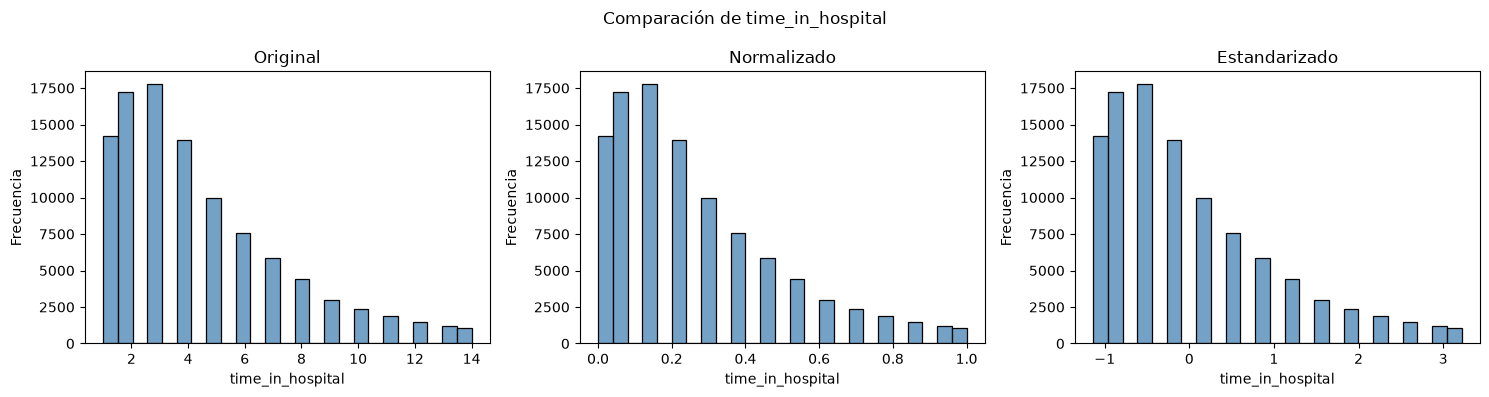

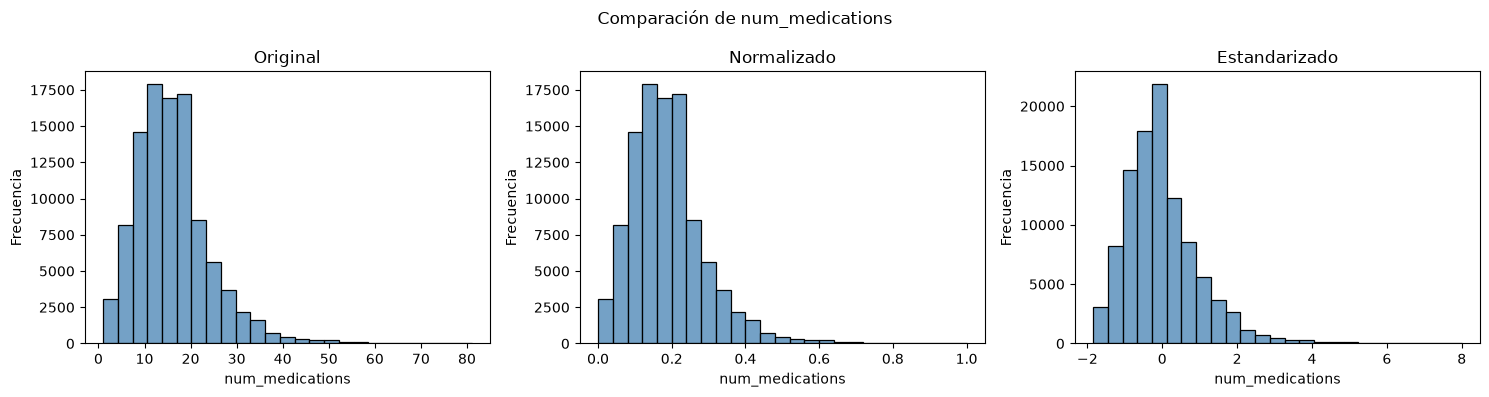

In [79]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar dos variables
variables_graficos = [
    "time_in_hospital",
    "num_medications"
]

# Crear tres gráficos por variable
for columna in variables_graficos:

    versiones = [
        ("Original", df_limpio),
        ("Normalizado", datos_normalizados),
        ("Estandarizado", datos_estandarizados)
    ]

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4)
    )

    for ax, (nombre, datos) in zip(axes, versiones):
        sns.histplot(
            datos[columna],
            bins=25,
            color="steelblue",
            ax=ax
        )

        ax.set_title(nombre)
        ax.set_xlabel(columna)
        ax.set_ylabel("Frecuencia")

    fig.suptitle(
        f"Comparación de {columna}"
    )

    plt.tight_layout()
    plt.show()



### Interpretación de gráficos comparativos

Se compararon las distribuciones de `time_in_hospital` y `num_medications` mediante histogramas de los datos originales, normalizados y estandarizados.

La normalización Min-Max reduce la escala de cada variable al intervalo de 0 a 1.

La estandarización Z-score modifica los valores para representarlos en desviaciones estándar respecto a la media.

Los gráficos permiten observar que la forma general de cada distribución se conserva, aunque sus valores y unidades cambien.

**Conclusión:** Ambas técnicas permiten transformar las escalas de los datos, pero no eliminan automáticamente los valores extremos ni corrigen distribuciones asimétricas.


In [80]:

# Elegir la variable time_in_hospital
columna = "time_in_hospital"

# Seleccionar cinco valores originales
valores = df_limpio[columna].head(5)

# Obtener parámetros de la variable
minimo = df_limpio[columna].min()
maximo = df_limpio[columna].max()
media = df_limpio[columna].mean()
desviacion = df_limpio[columna].std(ddof=0)

# Realizar los cálculos manuales
minmax_manual = (valores - minimo) / (maximo - minimo)
zscore_manual = (valores - media) / desviacion

# Comparar resultados con Scikit-learn
tabla_manual = pd.DataFrame({
    "Original": valores,
    "Min-Max manual": minmax_manual,
    "Min-Max Python": datos_normalizados.loc[
        valores.index, columna
    ],
    "Z-score manual": zscore_manual,
    "Z-score Python": datos_estandarizados.loc[
        valores.index, columna
    ]
})

print("Parámetros de la variable:")
print("Mínimo:", minimo)
print("Máximo:", maximo)
print("Media:", round(media, 6))
print("Desviación:", round(desviacion, 6))

display(tabla_manual.round(6))

assert np.allclose(
    tabla_manual["Min-Max manual"],
    tabla_manual["Min-Max Python"]
)

assert np.allclose(
    tabla_manual["Z-score manual"],
    tabla_manual["Z-score Python"]
)

print("Comprobación manual exitosa.")


Parámetros de la variable:
Mínimo: 1
Máximo: 14
Media: 4.395987
Desviación: 2.985093


,Original,Min-Max manual,Min-Max Python,Z-score manual,Z-score Python
0,1,0.000000,0.000000,-1.137649,-1.137649
1,3,0.153846,0.153846,-0.467653,-0.467653
2,2,0.076923,0.076923,-0.802651,-0.802651
3,2,0.076923,0.076923,-0.802651,-0.802651
4,1,0.000000,0.000000,-1.137649,-1.137649


Comprobación manual exitosa.



### Comprobación manual de normalización y estandarización

Se seleccionaron los primeros cinco valores de la variable `time_in_hospital` para realizar los cálculos de Min-Max y Z-score.

En la normalización se utilizaron los valores mínimo y máximo originales.

En la estandarización se utilizaron la media y la desviación estándar poblacional.

Posteriormente, los resultados se compararon con las transformaciones realizadas mediante Scikit-learn.

**Interpretación:** Los cálculos permiten comprobar que las dos técnicas de escalamiento fueron implementadas correctamente, siempre que las diferencias entre las operaciones manuales y las automáticas estén dentro de la tolerancia numérica.


In [81]:

# Verificar la correspondencia de filas
assert df_limpio.index.equals(datos_normalizados.index)
assert df_limpio.index.equals(datos_estandarizados.index)

# Guardar los datos normalizados
datos_normalizados.to_csv(
    "datos_normalizados.csv",
    index=False
)

# Guardar los datos estandarizados
datos_estandarizados.to_csv(
    "datos_estandarizados.csv",
    index=False
)

# Guardar correspondencia con registros originales
correspondencia = df[
    ["encounter_id", "patient_nbr"]
].copy()

correspondencia.insert(
    0,
    "fila_original",
    np.arange(len(df))
)

correspondencia.to_csv(
    "correspondencia_registros.csv",
    index=False
)

print("Archivos exportados correctamente.")
print("datos_normalizados.csv")
print("datos_estandarizados.csv")
print("comparacion_estadistica.csv")
print("diccionario_variables.csv")
print("correspondencia_registros.csv")


Archivos exportados correctamente.
datos_normalizados.csv
datos_estandarizados.csv
comparacion_estadistica.csv
diccionario_variables.csv
correspondencia_registros.csv



### Exportación de resultados

Se exportaron los conjuntos de datos normalizados y estandarizados en formato CSV.

Ambos archivos contienen las mismas siete variables y mantienen el orden de las hospitalizaciones originales.

Además, se generó un archivo de correspondencia con los identificadores originales y una tabla de comparación estadística.

**Resultado:** Los archivos permiten conservar, consultar y comparar los resultados de las transformaciones realizadas.



## Conclusiones generales

La práctica permitió aplicar las primeras tres fases de la metodología CRISP-DM al análisis de datos médicos de pacientes con diabetes.

Se analizaron 101.766 hospitalizaciones correspondientes a 71.518 pacientes únicos, identificando que un paciente puede presentar varios registros de hospitalización.

En el análisis exploratorio se identificaron valores faltantes, se revisaron duplicados y se construyeron gráficos para comprender la distribución de las variables cuantitativas.

La distribución de readmisiones mostró que el 53,91 % corresponde a registros sin readmisión, el 34,93 % a readmisiones posteriores a 30 días y el 11,16 % a readmisiones antes de 30 días.

Mediante el método IQR se identificaron 2.252 valores atípicos en `time_in_hospital` y 2.557 en `num_medications`. Estos se conservaron debido a que pueden representar hospitalizaciones válidas.

La normalización Min-Max permitió transformar las siete variables cuantitativas a un intervalo de 0 a 1, mientras que la estandarización Z-score permitió expresarlas en relación con la media y desviación estándar.

Se concluye que ambas técnicas son útiles para preparar datos antes de desarrollar modelos de Machine Learning, aunque no corrigen por sí mismas los problemas de calidad ni la asimetría de las distribuciones.

Los resultados corresponden a un análisis académico descriptivo y no permiten emitir diagnósticos médicos ni establecer relaciones causales.



## Preguntas de reflexión

### 1. ¿Por qué un código categórico numérico no debe escalarse como una medición?

Porque representa categorías y no cantidades. Aplicar escalamiento podría introducir distancias numéricas que no corresponden al significado real de esas categorías.

### 2. ¿Cómo afectaría un valor extremo a Min-Max y Z-score?

En Min-Max, un valor extremo puede provocar que la mayoría de los registros se concentren en un intervalo pequeño. En Z-score, puede modificar la media y desviación estándar utilizadas para transformar los datos.

### 3. ¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?

Porque un mismo paciente puede ingresar varias veces al hospital. Cada hospitalización representa un evento independiente que puede contener información válida.

### 4. ¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?

Cambiar de escala modifica la magnitud de los valores, mientras que corregir una distribución asimétrica implica aplicar transformaciones que cambien su forma.

### 5. ¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?

Primero dividiría los datos en entrenamiento y prueba, evitando que registros del mismo paciente aparezcan en ambos conjuntos. Luego ajustaría los escaladores únicamente con los datos de entrenamiento y transformaría los demás conjuntos utilizando los parámetros obtenidos.



## Referencias bibliográficas

Clore, J., Cios, K., DeShazo, J. y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008*. UCI Machine Learning Repository.

https://doi.org/10.24432/C5230J

Scikit-learn. Documentación de `MinMaxScaler`.

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

Scikit-learn. Documentación de `StandardScaler`.

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

### Asistencia externa

Se utilizó ChatGPT como herramienta de apoyo para la estructuración del código Python, la explicación de los procedimientos y la redacción de interpretaciones. La ejecución y verificación de resultados se realizó en Jupyter Notebook.
